In [1]:
import pandas as pd
import joblib
import json

# Load saved model and metadata
model = joblib.load(
    "models/rejection_risk_pipeline.joblib"
)

with open("models/model_metadata.json") as f:
    metadata = json.load(f)

threshold = metadata["threshold"]
features = metadata["features"]

# Use the counterparty from your actual T-1001 fixture
t1001_counterparty = "CP-004"

# Original and corrected versions
t1001_df = pd.DataFrame([
    {
        "trade_id": "T-1001",
        "trade_version": 1,
        "notional_amount": 100_000_000,
        "tenor_years": 10,
        "currency": "GBP",
        "product_type": "GBP_IRS",
        "counterparty_id": t1001_counterparty
    },
    {
        "trade_id": "T-1001",
        "trade_version": 2,
        "notional_amount": 10_000_000,
        "tenor_years": 10,
        "currency": "GBP",
        "product_type": "GBP_IRS",
        "counterparty_id": t1001_counterparty
    }
])

display(t1001_df)

,trade_id,trade_version,notional_amount,tenor_years,currency,product_type,counterparty_id
0,T-1001,1,100000000,10,GBP,GBP_IRS,CP-004
1,T-1001,2,10000000,10,GBP,GBP_IRS,CP-004


In [3]:
##  Generate predictions

# Verified T-1001 counterparty
t1001_counterparty = "CP-004"

# Predict rejection probabilities
t1001_df["risk_probability"] = model.predict_proba(
    t1001_df[features]
)[:, 1]

# Apply saved threshold
t1001_df["risk_flag"] = (
    t1001_df["risk_probability"] >= threshold
).map({
    True: "Review Required",
    False: "Below Threshold"
})

t1001_df["model_version"] = metadata["model_version"]

display(t1001_df[
    [
        "trade_id",
        "trade_version",
        "notional_amount",
        "risk_probability",
        "risk_flag",
        "model_version"
    ]
])

,trade_id,trade_version,notional_amount,risk_probability,risk_flag,model_version
0,T-1001,1,100000000,0.182520,Review Required,1.0.0
1,T-1001,2,10000000,0.078747,Below Threshold,1.0.0


c:\Users\singh\anaconda3\envs\NorthBridge_TradeFlow\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 1400 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1400 when initializing the masker.


Total transformed features: 9

Trade T-1001 — version 1
Risk probability: 18.25%
Risk flag: Review Required


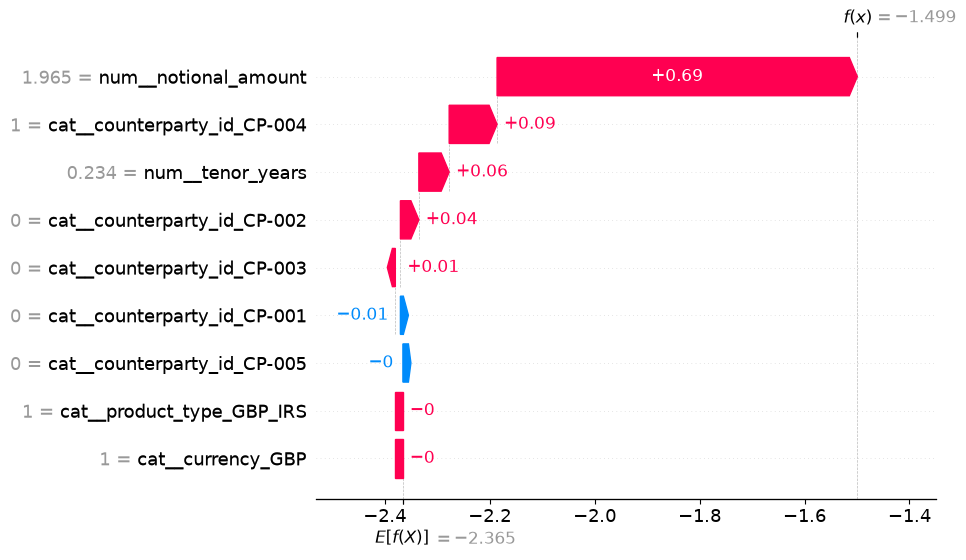


Trade T-1001 — version 2
Risk probability: 7.87%
Risk flag: Below Threshold


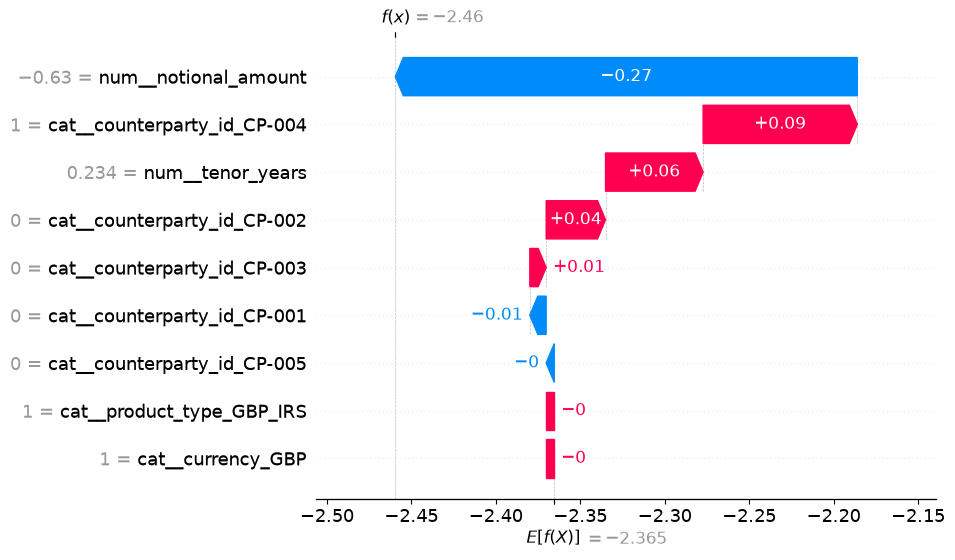

In [6]:
## Explain T-1001 with SHAP
import joblib
import shap
import pandas as pd
from scipy import sparse

# Reload the saved pipeline
model = joblib.load("models/rejection_risk_pipeline.joblib")

classifier = model.named_steps["classifier"]
transformer = model.named_steps["preprocessor"]

# Set the confirmed counterparty for both trade versions
t1001_counterparty = "CP-004"
t1001_df["counterparty_id"] = t1001_counterparty

# Recreate the training background from the same CSV used in notebook 01
history = pd.read_csv(
    "data/Synthetic_data/synthetic_trade_history.csv"
)

history["trade_timestamp"] = pd.to_datetime(
    history["trade_timestamp"],
    format="%d/%m/%Y"
)

history = history.sort_values(
    ["trade_timestamp", "trade_id", "trade_version"]
).reset_index(drop=True)

trade_order = (
    history.groupby("trade_id")["trade_timestamp"]
    .min()
    .sort_values()
)

train_end = int(len(trade_order) * 0.70)
train_ids = set(trade_order.index[:train_end])

X_background_raw = history.loc[
    history["trade_id"].isin(train_ids), features
]

# Apply fitted preprocessing without retraining
X_background = transformer.transform(X_background_raw)
X_t1001 = transformer.transform(t1001_df[features])

if sparse.issparse(X_background):
    X_background = X_background.toarray()

if sparse.issparse(X_t1001):
    X_t1001 = X_t1001.toarray()

feature_names = list(transformer.get_feature_names_out())
print("Total transformed features:", len(feature_names))

# Refresh predictions for the confirmed counterparty
t1001_df["risk_probability"] = model.predict_proba(
    t1001_df[features]
)[:, 1]

t1001_df["risk_flag"] = (
    t1001_df["risk_probability"] >= threshold
).map({
    True: "Review Required",
    False: "Below Threshold"
})

# Calculate SHAP values
explainer = shap.LinearExplainer(
    classifier,
    X_background,
    feature_names=feature_names
)

t1001_shap = explainer(X_t1001)

# SHAP contributions for Logistic Regression are in log-odds
for i, row in t1001_df.reset_index(drop=True).iterrows():
    print(
        f"\nTrade {row['trade_id']} — version {row['trade_version']}"
        f"\nRisk probability: {row['risk_probability']:.2%}"
        f"\nRisk flag: {row['risk_flag']}"
    )
    shap.plots.waterfall(t1001_shap[i], max_display=10)

In [7]:
## Save prediction evidence
from datetime import datetime, timezone
from pathlib import Path

evidence_dir = Path("evidence")
evidence_dir.mkdir(parents=True, exist_ok=True)

# Refresh predictions so the evidence matches the current inputs
t1001_df["risk_probability"] = model.predict_proba(
    t1001_df[features]
)[:, 1]

t1001_df["risk_flag"] = (
    t1001_df["risk_probability"] >= threshold
).map({
    True: "Review Required",
    False: "Below Threshold"
})

# Record model and scoring details
t1001_df["decision_threshold"] = threshold
t1001_df["model_version"] = metadata["model_version"]
t1001_df["scored_at_utc"] = datetime.now(timezone.utc).isoformat()

evidence_columns = list(dict.fromkeys([
    "trade_id",
    "trade_version",
    *features,
    "risk_probability",
    "risk_flag",
    "decision_threshold",
    "model_version",
    "scored_at_utc"
]))

output_path = evidence_dir / "T1001_model_predictions.csv"

t1001_df[evidence_columns].to_csv(output_path, index=False)

print(f"T-1001 prediction evidence saved:\n{output_path.resolve()}")
display(t1001_df[evidence_columns])

T-1001 prediction evidence saved:
D:\STUDY\Data_Science_Courses\PROJECTS\14.NorthBridge TradeFlow\NorthBridge-TradeFlow\Phase_5_Data Science and Predictive Intelligence\notebook\evidence\T1001_model_predictions.csv


,trade_id,trade_version,notional_amount,tenor_years,currency,product_type,counterparty_id,risk_probability,risk_flag,decision_threshold,model_version,scored_at_utc
0,T-1001,1,100000000,10,GBP,GBP_IRS,CP-004,0.182520,Review Required,0.1,1.0.0,2026-11-08T21:27:14.014449+00:00
1,T-1001,2,10000000,10,GBP,GBP_IRS,CP-004,0.078747,Below Threshold,0.1,1.0.0,2026-11-08T21:27:14.014449+00:00
